# Chapter 3 — Classification: MNIST

A hands-on walk-through transitioning from regression to **classification**:
- **Dataset**: MNIST (70,000 grayscale images of handwritten digits $0–9$, $28 \times 28$ pixels $= 784$ features).
- **Goal**: Master binary classification, metrics (Confusion Matrix, Precision, Recall, $F_1$, ROC, PR curve), multiclass strategies (OvA vs. OvO), Error Analysis, and Multilabel/Multioutput classification.

## 1. Setup & Starter Imports

Standard imports for data handling, plotting, and Scikit-Learn models and metrics.

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from sklearn.utils import Bunch
from sklearn.linear_model import SGDClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    roc_curve,
    roc_auc_score,
)

%matplotlib inline
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)
np.random.seed(42)

print("Setup complete!")

Setup complete!


## 2. Load MNIST Dataset

Using local cached mirror to load 70,000 digits.

In [2]:
def load_mnist():
    data_dir = os.path.join("..", "data")
    if not os.path.exists(data_dir):
        data_dir = os.path.join("week1", "day2", "data")
    os.makedirs(data_dir, exist_ok=True)
    mnist_path = os.path.join(data_dir, "mnist.npz")
    
    if not os.path.exists(mnist_path):
        url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
        urllib.request.urlretrieve(url, mnist_path)
    
    with np.load(mnist_path) as npz:
        x_train, y_train = npz["x_train"], npz["y_train"]
        x_test, y_test = npz["x_test"], npz["y_test"]
    
    X = np.concatenate([x_train.reshape(-1, 784), x_test.reshape(-1, 784)], axis=0)
    y = np.concatenate([y_train.astype(str), y_test.astype(str)], axis=0)
    return Bunch(data=X, target=y, DESCR="MNIST 70k 28x28 digits")

mnist = load_mnist()
X, y = mnist["data"], mnist["target"]
print(f"X shape: {X.shape} | y shape: {y.shape}")

X shape: (70000, 784) | y shape: (70000,)

## 3. Visualizing Digits

Reshape any 784-dim pixel array into $28 \times 28$ and display with `plt.imshow(cmap="binary")`.

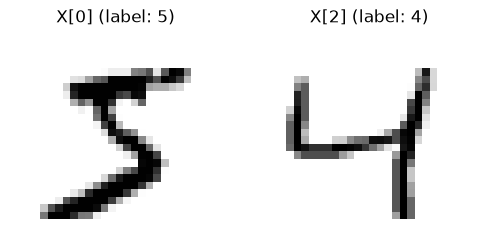

In [3]:
def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

# Inspect sample 0 (label: 5) and sample 2 (label: 4)
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(X[0].reshape(28, 28), cmap="binary")
axes[0].set_title(f"X[0] (label: {y[0]})")
axes[0].axis("off")

axes[1].imshow(X[2].reshape(28, 28), cmap="binary")
axes[1].set_title(f"X[2] (label: {y[2]})")
axes[1].axis("off")
plt.show()

## 4. Train / Test Split

MNIST is already split into the first 60,000 images for training and the last 10,000 for testing.
The training data is pre-shuffled to ensure all cross-validation folds have similar digit distributions.

In [4]:
y = y.astype(np.uint8)

X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]
some_digit = X_train[0]  # Digit 5

print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

Train samples: 60000 | Test samples: 10000


## 5. Training a Binary Classifier (The "5-Detector")

We start with a binary classification problem: distinguishing between "is a 5" (`True`) and "not a 5" (`False`).
`SGDClassifier` is capable of handling large datasets efficiently by updating weights instance-by-instance (online learning).

In [5]:
# Create boolean target vectors: True for all 5s, False for others
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

print("Predict some_digit (is 5):", sgd_clf.predict([some_digit])[0])
print("Predict X[2] (is 4):      ", sgd_clf.predict([X[2]])[0])

Predict some_digit (is 5): True
Predict X[2] (is 4):       False


### Custom Implementation of Cross-Validation (Under the Hood)

Using `StratifiedKFold` to generate stratified folds (preserving the ~10% ratio of 5s across folds) and training cloned models from scratch.

In [6]:
skfolds = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for fold, (train_index, test_index) in enumerate(skfolds.split(X_train, y_train_5), 1):
    clone_clf = clone(sgd_clf)
    X_train_folds = X_train[train_index]
    y_train_folds = y_train_5[train_index]
    X_test_fold = X_train[test_index]
    y_test_fold = y_train_5[test_index]
    
    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_fold)
    n_correct = sum(y_pred == y_test_fold)
    print(f"Fold {fold} Accuracy: {n_correct / len(y_pred):.4f}")

Fold 1 Accuracy: 0.9042


Fold 2 Accuracy: 0.9477


Fold 3 Accuracy: 0.9678


## 6. Measuring Accuracy & The Accuracy Trap

Evaluating `SGDClassifier` using 3-fold cross-validation gives **~95-96% accuracy**.
- **The Trap**: Only ~10% of images are 5s (90% are not 5s). A dummy classifier that *always* predicts `False` ("never-5") achieves **~91% accuracy**!
- > ⚠️ **Golden Rule**: **Accuracy is often misleading on skewed/imbalanced datasets.** Never rely on accuracy alone.

In [7]:
# 1. 3-Fold Cross-Validation on SGD Classifier
sgd_acc_scores = cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")
print(f"SGD Classifier CV Accuracy:   {sgd_acc_scores.round(4)} (Mean: {sgd_acc_scores.mean():.2%})")

# 2. Baseline Dummy Classifier (always predicts False)
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_acc_scores = cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")
print(f"Dumb 'Never-5' Model Accuracy: {dummy_acc_scores.round(4)} (Mean: {dummy_acc_scores.mean():.2%})")

SGD Classifier CV Accuracy:   [0.9504 0.9604 0.9604] (Mean: 95.70%)
Dumb 'Never-5' Model Accuracy: [0.9096 0.9096 0.9096] (Mean: 90.96%)


## 7. Confusion Matrix

The confusion matrix counts how many times instances of class A were classified as class B.
`cross_val_predict()` generates clean out-of-fold predictions using models trained on other folds.

In [8]:
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)
cm = confusion_matrix(y_train_5, y_train_pred)

print("Confusion Matrix:")
print(cm)
print(f"\nTN (correct non-5s): {cm[0, 0]} | FP (wrongly called 5): {cm[0, 1]}")
print(f"FN (missed 5s):      {cm[1, 0]}  | TP (correctly detected 5s): {cm[1, 1]}")

Confusion Matrix:
[[53892   687]
 [ 1891  3530]]

TN (correct non-5s): 53892 | FP (wrongly called 5): 687
FN (missed 5s):      1891  | TP (correctly detected 5s): 3530


## 8. Precision, Recall, and $F_1$ Score

- **Precision** $= \frac{TP}{TP + FP}$: Quality of positive predictions (*"When it claims an image is a 5, is it right?"*).
- **Recall (Sensitivity)** $= \frac{TP}{TP + FN}$: Completeness (*"What fraction of all actual 5s did it find?"*).
- **$F_1$ Score** $= 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$: Harmonic mean balancing both.

In [9]:
prec = precision_score(y_train_5, y_train_pred)
rec = recall_score(y_train_5, y_train_pred)
f1 = f1_score(y_train_5, y_train_pred)

print(f"Precision: {prec:.4f} ({prec:.2%})")
print(f"Recall:    {rec:.4f} ({rec:.2%})")
print(f"F1 Score:  {f1:.4f} ({f1:.2%})")
print("\nSummary: When claiming an image is a 5, it is right ~83.7% of the time, but only catches ~65.1% of all 5s.")

Precision: 0.8371 (83.71%)
Recall:    0.6512 (65.12%)
F1 Score:  0.7325 (73.25%)

Summary: When claiming an image is a 5, it is right ~83.7% of the time, but only catches ~65.1% of all 5s.


## 9. The ROC Curve & ROC AUC

The **Receiver Operating Characteristic (ROC)** curve plots the **True Positive Rate (Recall)** against the **False Positive Rate (FPR)** across all decision thresholds.

$$\text{TPR (Recall)} = \frac{TP}{TP + FN}, \quad \text{FPR} = \frac{FP}{TN + FP} = 1 - \text{Specificity}$$

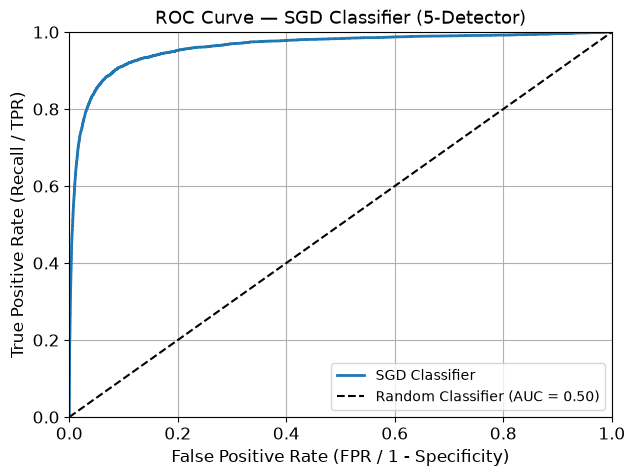

ROC AUC Score: 0.9605 (96.05%)


In [10]:
# 1. Obtain decision scores via decision_function
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method="decision_function")
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

# 2. Plotting helper function
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier (AUC = 0.50)")
    plt.axis([0, 1, 0, 1])
    plt.xlabel("False Positive Rate (FPR / 1 - Specificity)", fontsize=12)
    plt.ylabel("True Positive Rate (Recall / TPR)", fontsize=12)
    plt.grid(True)
    if label:
        plt.legend(loc="lower right")

plt.figure(figsize=(7, 5))
plot_roc_curve(fpr, tpr, label="SGD Classifier")
plt.title("ROC Curve — SGD Classifier (5-Detector)", fontsize=13)
plt.show()

auc_score = roc_auc_score(y_train_5, y_scores)
print(f"ROC AUC Score: {auc_score:.4f} ({auc_score:.2%})")

> ⚠️ **Rule of Thumb (PR vs. ROC Curve):**
> - **Use PR Curve**: When the positive class is **rare / imbalanced** (like our 5s where only 10% are positive) or when avoiding false alarms is critical.
> - **Use ROC Curve**: When classes are roughly **balanced** or when false negatives are much worse.
> *(The ROC curve looks deceptively great at 96% AUC because the 90% non-5s make the denominator $TN + FP$ huge, keeping FPR tiny!)*

## 10. Comparing SGDClassifier vs. RandomForestClassifier (ROC vs. PR Discussion)

`RandomForestClassifier` does not have a `decision_function()`; instead, it provides `predict_proba()`. We pass the probability of the positive class (`[:, 1]`) to `roc_curve()`.

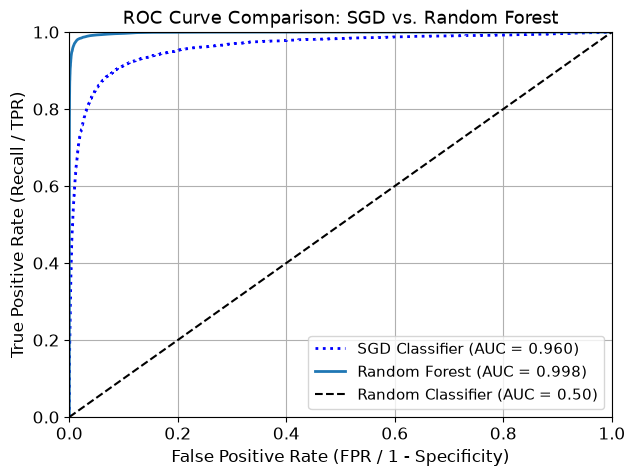

Random Forest ROC AUC:   0.9983 (99.83%)
Random Forest Precision: 0.9897 (98.97%)
Random Forest Recall:    0.8725 (87.25%)


In [11]:
forest_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv=3,
                                    method="predict_proba", n_jobs=-1)

y_scores_forest = y_probas_forest[:, 1]
fpr_forest, tpr_forest, thresholds_forest = roc_curve(y_train_5, y_scores_forest)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, "b:", linewidth=2, label="SGD Classifier (AUC = 0.960)")
plot_roc_curve(fpr_forest, tpr_forest, label="Random Forest (AUC = 0.998)")
plt.legend(loc="lower right", fontsize=11)
plt.title("ROC Curve Comparison: SGD vs. Random Forest", fontsize=13)
plt.show()

forest_auc = roc_auc_score(y_train_5, y_scores_forest)
y_train_pred_forest = (y_scores_forest >= 0.5)
forest_prec = precision_score(y_train_5, y_train_pred_forest)
forest_rec = recall_score(y_train_5, y_train_pred_forest)

print(f"Random Forest ROC AUC:   {forest_auc:.4f} ({forest_auc:.2%})")
print(f"Random Forest Precision: {forest_prec:.4f} ({forest_prec:.2%})")
print(f"Random Forest Recall:    {forest_rec:.4f} ({forest_rec:.2%})")

## 11. Multiclass Classification (OvA vs. OvO)

While binary classification predicts between 2 classes (e.g., 5 vs. not-5), **multiclass classification** distinguishes between all 10 digits (0 through 9).

- **One-versus-All (OvA / OvR)**: Train 10 binary classifiers (0-detector, 1-detector, etc.). Pick the class with the highest decision score (Scikit-Learn default for `SGDClassifier`).
- **One-versus-One (OvO)**: Train $\frac{N(N-1)}{2} = 45$ pairwise classifiers (0 vs 1, 0 vs 2, etc.). Pick the digit that wins the most duels (preferred for algorithms like SVMs that scale poorly with dataset size).

> 💡 **Scikit-Learn Magic**: When you pass multiclass labels (`y_train`, 0–9) to `SGDClassifier`, Scikit-Learn automatically detects it and runs **OvA** under the hood!

In [12]:
# 1. Train SGDClassifier on the multiclass dataset
sgd_clf_multi = SGDClassifier(random_state=42)
sgd_clf_multi.fit(X_train, y_train)

# 2. Predict on some_digit (digit 5)
pred = sgd_clf_multi.predict([some_digit])
print(f"Prediction for some_digit (Actual: {y_train[0]}):", pred[0])

# 3. Inspect all 10 decision scores
scores = sgd_clf_multi.decision_function([some_digit])
print("\nAll 10 Decision Scores:\n", scores.round(2))
print("Winning class index (max score):", np.argmax(scores))
print("Classes array:                  ", sgd_clf_multi.classes_)

Prediction for some_digit (Actual: 5): 3

All 10 Decision Scores:
 [[-31893.03 -19047.56  -9530.64   1823.73 -22320.15  -1385.8  -26188.91
  -16147.51  -4604.35 -12050.77]]
Winning class index (max score): 3
Classes array:                   [0 1 2 3 4 5 6 7 8 9]


### 💡 The `StandardScaler` Boost (Feature Scaling)

- **What it does**: Rescales pixel values so they have an **average of 0** and a **standard deviation of 1**.
- **Why it matters**: `SGDClassifier` relies on Gradient Descent. Scaling eliminates distorted elongated valleys, allowing GD to march directly to the minimum.
- **The Result**: Evaluated below, scaling boosts accuracy from **~86% $\to$ ~90%**!

In [13]:
# 1. Evaluate raw SGD multiclass cross-validation accuracy (~86%)
raw_scores = cross_val_score(sgd_clf_multi, X_train[:15000], y_train[:15000], cv=3, scoring="accuracy", n_jobs=-1)
print(f"Raw SGD Multiclass CV Accuracy:    {raw_scores.round(4)} (Mean: {raw_scores.mean():.2%})")

# 2. Scale features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype(np.float32))

# 3. Evaluate scaled SGD multiclass cross-validation accuracy (~90%)
scaled_scores = cross_val_score(sgd_clf_multi, X_train_scaled[:15000], y_train[:15000], cv=3, scoring="accuracy", n_jobs=-1)
print(f"Scaled SGD Multiclass CV Accuracy: {scaled_scores.round(4)} (Mean: {scaled_scores.mean():.2%})")

Raw SGD Multiclass CV Accuracy:    [0.8784 0.8732 0.8546] (Mean: 86.87%)


Scaled SGD Multiclass CV Accuracy: [0.9046 0.8976 0.8884] (Mean: 89.69%)


## 12. Error Analysis

To improve our model, we analyze its classification errors:
1. **Raw Confusion Matrix**: Verify that most predictions sit on the main diagonal.
2. **Normalized Error Matrix**: Divide each row by the class total to get error rates and zero out the diagonal so error hotspots light up brightly.
3. **Inspect Individual Errors**: Examine specific confused digit pairs (e.g., 3s vs. 5s).

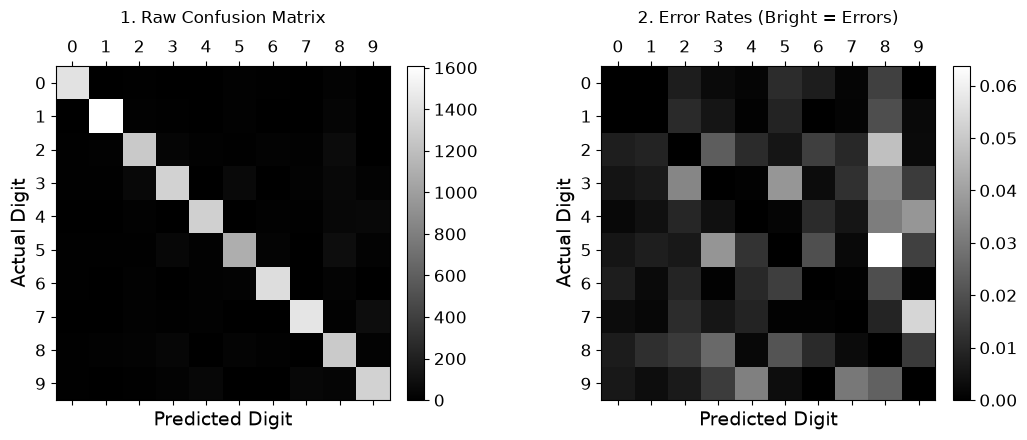

In [14]:
# 1. Get out-of-fold predictions on scaled training set
y_train_pred_multi = cross_val_predict(sgd_clf_multi, X_train_scaled[:15000], y_train[:15000], cv=3, n_jobs=-1)

# 2. Raw confusion matrix
conf_mx = confusion_matrix(y_train[:15000], y_train_pred_multi)

# 3. Normalized error matrix (divide by row sums and zero out diagonals)
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums
np.fill_diagonal(norm_conf_mx, 0)

# 4. Display both matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

im0 = axes[0].matshow(conf_mx, cmap=plt.cm.gray)
axes[0].set_title("1. Raw Confusion Matrix", pad=12)
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].matshow(norm_conf_mx, cmap=plt.cm.gray)
axes[1].set_title("2. Error Rates (Bright = Errors)", pad=12)
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlabel("Predicted Digit")
    ax.set_ylabel("Actual Digit")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

plt.tight_layout()
plt.show()

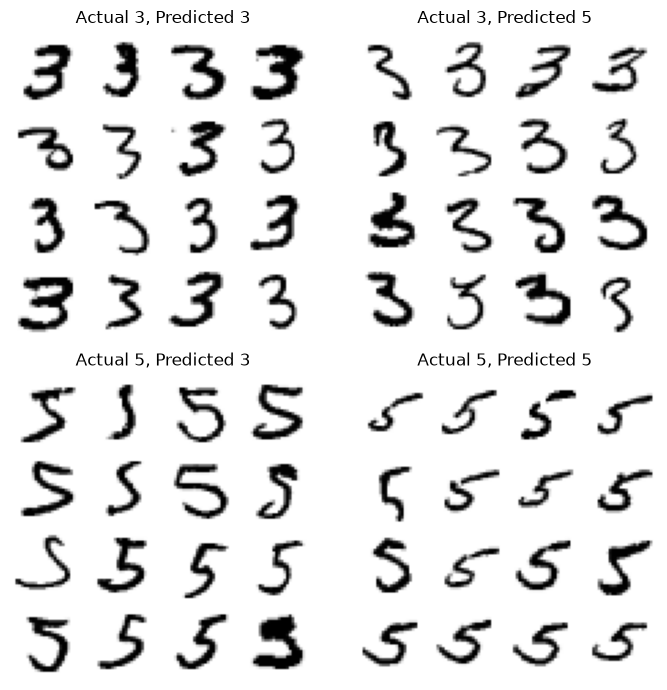

In [15]:
# Helper function to plot digits in a grid
def plot_digits(instances, images_per_row=5, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)
    images = [instance.reshape(size, size) for instance in instances]
    n_rows = (len(instances) - 1) // images_per_row + 1
    row_images = []
    n_empty = n_rows * images_per_row - len(instances)
    images.append(np.zeros((size, size * n_empty)))
    for row in range(n_rows):
        rimages = images[row * images_per_row : (row + 1) * images_per_row]
        row_images.append(np.concatenate(rimages, axis=1))
    image = np.concatenate(row_images, axis=0)
    plt.imshow(image, cmap=plt.cm.binary, **options)
    plt.axis("off")

# Compare correctly classified vs. misclassified 3s and 5s
cl_a, cl_b = 3, 5
y_sub = y_train[:15000]
X_sub = X_train[:15000]

X_aa = X_sub[(y_sub == cl_a) & (y_train_pred_multi == cl_a)]
X_ab = X_sub[(y_sub == cl_a) & (y_train_pred_multi == cl_b)]
X_ba = X_sub[(y_sub == cl_b) & (y_train_pred_multi == cl_a)]
X_bb = X_sub[(y_sub == cl_b) & (y_train_pred_multi == cl_b)]

plt.figure(figsize=(7, 7))
plt.subplot(221); plot_digits(X_aa[:16], images_per_row=4); plt.title(f"Actual {cl_a}, Predicted {cl_a}")
plt.subplot(222); plot_digits(X_ab[:16], images_per_row=4); plt.title(f"Actual {cl_a}, Predicted {cl_b}")
plt.subplot(223); plot_digits(X_ba[:16], images_per_row=4); plt.title(f"Actual {cl_b}, Predicted {cl_a}")
plt.subplot(224); plot_digits(X_bb[:16], images_per_row=4); plt.title(f"Actual {cl_b}, Predicted {cl_b}")
plt.tight_layout()
plt.show()

## 13. Multilabel Classification

In some cases we want a classifier to output multiple binary labels for each instance:
- For example, predict two properties simultaneously: ["Is the digit large ($\ge 7$)?", "Is the digit odd?"].
- `KNeighborsClassifier` supports multiple binary labels natively.

In [16]:
# 1. Construct multilabel target array: [is_large, is_odd]
y_train_large = (y_train >= 7)
y_train_odd = (y_train % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd]

# 2. Train KNeighborsClassifier
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train[:10000], y_multilabel[:10000])

# 3. Predict on some_digit (digit 5: not large [False], but odd [True])
multilabel_pred = knn_clf.predict([some_digit])
print("Multilabel prediction for digit 5 [is_large (>=7), is_odd]:", multilabel_pred[0])

Multilabel prediction for digit 5 [is_large (>=7), is_odd]: [False  True]


## 14. Multioutput Classification (Image Denoising)

A generalization of multilabel classification where each label can be multiclass (i.e., take on many values).
- **Example**: Denoising an image. Each of the 784 pixels is an output label ranging from 0 to 255.

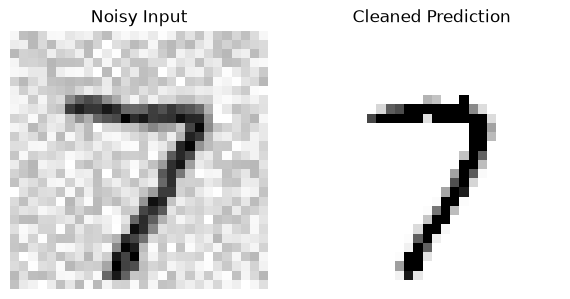

In [17]:
# 1. Add random noise to training and test digits
np.random.seed(42)
noise_train = np.random.randint(0, 100, (len(X_train[:5000]), 784))
noise_test = np.random.randint(0, 100, (len(X_test[:1000]), 784))

X_train_mod = X_train[:5000] + noise_train
y_train_mod = X_train[:5000]  # Clean original image is the target!

X_test_mod = X_test[:1000] + noise_test
y_test_mod = X_test[:1000]

# 2. Train KNN on noisy inputs to predict clean pixels
knn_clf.fit(X_train_mod, y_train_mod)

# 3. Predict cleaned image for a test sample
some_index = 0
clean_digit_pred = knn_clf.predict([X_test_mod[some_index]])

# 4. Display noisy vs. cleaned image
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(X_test_mod[some_index].reshape(28, 28), cmap="binary")
axes[0].set_title("Noisy Input")
axes[0].axis("off")

axes[1].imshow(clean_digit_pred.reshape(28, 28), cmap="binary")
axes[1].set_title("Cleaned Prediction")
axes[1].axis("off")
plt.tight_layout()
plt.show()